# 4. A new setup, no label

Can a model say wood / metal / textile / polymer on a recording setup it has never seen, without any label from it?

Here we try the simplest idea with a pretrained model: **CLAP** puts sounds and sentences in the same space.
We write a few sentences per family ("the sound of scraping wood"...) and take the family whose sentences are
closest to the sound. Nothing is trained.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchaudio
from sklearn.metrics import balanced_accuracy_score
from transformers import ClapModel, ClapProcessor

FAMILIES = ["wood", "metal", "textile", "polymer"]
device = "cuda" if torch.cuda.is_available() else "cpu"
Path("cache").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

## The data

`data.ipynb` cuts every recording into windows of 0.5 s at 16 kHz, all at the same loudness.

In [2]:
saved = np.load("cache/sound_windows.npz", allow_pickle=True)
windows = saved["windows"]
info = pd.DataFrame({c: saved[c] for c in ["dataset", "recording", "surface", "family"]})

print(windows.shape)
info.groupby("dataset").agg(windows=("family", "size"), recordings=("recording", "nunique"), surfaces=("surface", "nunique"))

(15192, 8000)


,windows,recordings,surfaces
dataset,,,
Cluster,3690,864,72
Greatest Hits,1195,1195,503
LMT108,3456,432,36
LMT69,2800,200,20
Phone pilot,703,26,5
SENS3,2880,360,30
TUM,468,234,117


## One CLAP vector per window

CLAP wants 48 kHz sound. This takes a few minutes the first time, then the vectors are read from `cache/`.

In [3]:
model = ClapModel.from_pretrained("laion/clap-htsat-unfused").to(device).eval()
processor = ClapProcessor.from_pretrained("laion/clap-htsat-unfused")

def clap_vectors(windows, file):
    if Path(file).exists():
        return np.load(file)
    vectors = []
    for start in range(0, len(windows), 32):
        batch = torch.tensor(windows[start : start + 32].astype(np.float32)) * 0.1
        batch = torchaudio.functional.resample(batch, 16000, 48000).numpy()
        inputs = processor(audio=list(batch), sampling_rate=48000, return_tensors="pt").to(device)
        with torch.no_grad():
            out = model.get_audio_features(**inputs).pooler_output
        vectors.append(torch.nn.functional.normalize(out, dim=-1).cpu().numpy())
    vectors = np.concatenate(vectors)
    np.save(file, vectors)
    return vectors


vectors = clap_vectors(windows, "cache/clap_vectors.npy")
vectors.shape

(15192, 512)

## One vector per family, from sentences

In [4]:
templates = [
    "the sound of scraping {}",
    "a stick scratching a {} surface",
    "rubbing a finger on {}",
    "friction noise of sliding on {}",
    "scratching {}",
]
words = {
    "wood": ["wood", "a wooden board", "timber"],
    "metal": ["metal", "steel", "aluminium"],
    "textile": ["fabric", "cloth", "textile"],
    "polymer": ["plastic", "rubber", "vinyl"],
}

text_vectors = []
for family in FAMILIES:
    sentences = [t.format(w) for t in templates for w in words[family]]
    inputs = processor(text=sentences, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        out = model.get_text_features(**inputs).pooler_output
    mean = torch.nn.functional.normalize(out, dim=-1).mean(0)
    text_vectors.append((mean / mean.norm()).cpu().numpy())
text_vectors = np.array(text_vectors)

## Reading a dataset

One vector per recording (the mean of its windows), then the closest family.

`centre=True` removes the mean vector of the dataset first. It uses the recordings of the new setup but not their
labels. We compare with and without.

In [5]:
def read_with_text(vectors, info, centre=True):
    per_recording = pd.DataFrame(vectors).groupby(info.recording.to_numpy()).mean()
    answers = info.drop_duplicates("recording").set_index("recording").loc[per_recording.index]
    families = [f for f in FAMILIES if f in set(answers.family)]

    v = per_recording.to_numpy()
    if centre:
        v = v - v.mean(axis=0)
    v = v / np.linalg.norm(v, axis=1, keepdims=True)
    cosine = v @ text_vectors[[FAMILIES.index(f) for f in families]].T
    if centre:
        cosine = cosine - cosine.mean(axis=0)
    answers["answer"] = np.array(families)[cosine.argmax(axis=1)]
    return answers


def score(answers):
    # some families have many more surfaces: we draw the same number in each, 30 times
    rng = np.random.default_rng(0)
    surfaces = answers.drop_duplicates("surface")
    families = [f for f in FAMILIES if f in set(answers.family)]
    n = surfaces.family.value_counts().min()
    scores = []
    for _ in range(30):
        kept = np.concatenate([rng.choice(surfaces.surface[surfaces.family == f], n, replace=False) for f in families])
        part = answers[answers.surface.isin(kept)]
        scores.append(balanced_accuracy_score(part.family, part.answer))
    return np.mean(scores)

## Scores

Chance is 0.25 (0.33 for TUM, which has no textile).

In [6]:
datasets = ["LMT108", "LMT69", "TUM", "SENS3", "Cluster", "Greatest Hits", "Phone pilot"]

answers = {}
table = pd.DataFrame(index=datasets, columns=["no centring", "centred"], dtype=float)
for d in datasets:
    rows = (info.dataset == d).to_numpy()
    table.loc[d, "no centring"] = score(read_with_text(vectors[rows], info[rows], centre=False))
    answers[d] = read_with_text(vectors[rows], info[rows])
    table.loc[d, "centred"] = score(answers[d])
table.loc["mean of the 6 public datasets"] = table.iloc[:6].mean()
table.to_csv("results/clap_text_scores.csv")
table.round(2)

,no centring,centred
LMT108,0.32,0.53
LMT69,0.51,0.65
TUM,0.36,0.34
SENS3,0.34,0.32
Cluster,0.26,0.24
Greatest Hits,0.34,0.48
Phone pilot,0.25,0.83
mean of the 6 public datasets,0.36,0.43


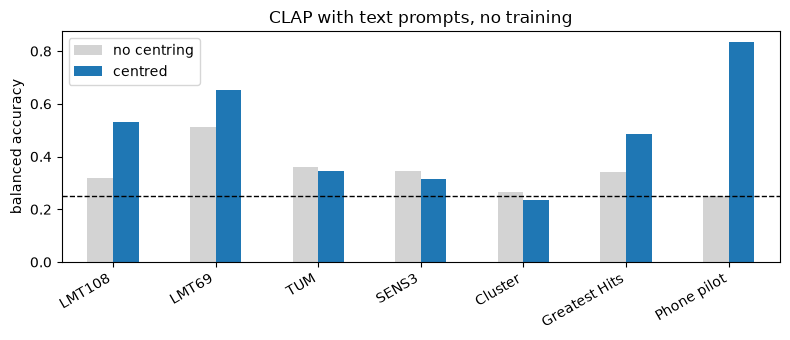

In [7]:
ax = table.iloc[:7].plot.bar(figsize=(8, 3.5), color=["lightgrey", "tab:blue"])
ax.axhline(0.25, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("balanced accuracy")
ax.set_title("CLAP with text prompts, no training")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("results/clap_text_scores.png", dpi=120)

## Which families does it get right?

In [8]:
recall = pd.DataFrame(index=FAMILIES)
for d in datasets:
    a = answers[d]
    recall[d] = (a.answer == a.family).groupby(a.family).mean()
recall.round(2)

,LMT108,LMT69,TUM,SENS3,Cluster,Greatest Hits,Phone pilot
wood,0.42,0.65,0.12,0.33,0.20,0.37,0.67
metal,0.72,1.00,0.32,0.42,0.31,0.63,1.00
textile,0.70,0.64,NaN,0.33,0.25,0.75,0.83
polymer,0.29,0.35,0.58,0.15,0.17,0.17,0.75


## A test we kept aside: a colleague's phone

A colleague recorded 28 scrapes with another phone (jeans, metal, plastic and wood objects, rubbed with a finger or
a tool). These files are never used for training or for any choice. Before listening we wrote the pass mark: 0.50.

In [9]:
saved = np.load("cache/colleague_windows.npz", allow_pickle=True)
colleague = pd.DataFrame({c: saved[c] for c in ["recording", "family", "tool"]})
colleague["surface"] = colleague.recording
colleague_vectors = clap_vectors(saved["windows"], "cache/clap_vectors_colleague.npy")

a = read_with_text(colleague_vectors, colleague)
print("balanced accuracy:", round(balanced_accuracy_score(a.family, a.answer), 2))
pd.crosstab(a.family, a.answer)

balanced accuracy: 0.45


answer,metal,polymer,textile,wood
family,,,,
metal,5,1,0,3
polymer,0,1,2,1
textile,0,0,9,0
wood,5,0,1,0


0.45: not passed. Jeans are always right, wood almost never.

## The other way: train on one setup, test on another

CLAP with text uses no label at all. The usual way is to train a classifier on a labeled setup and apply it to a
new one. We do it with the vibration: one BEATs vector per recording (as in `few_labels.ipynb`), standardized
inside each setup, then a logistic regression.

Cluster is a machine, LMT108 and HaTT are steel tips held by hand, SENS3 is a bare finger.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

saved = np.load("cache/vibration_vectors.npz", allow_pickle=True)
vib = pd.DataFrame({c: saved[c] for c in ["dataset", "surface", "family"]})
vib_vectors = saved["vectors"].copy()
for d in vib.dataset.unique():
    rows = (vib.dataset == d).to_numpy()
    vib_vectors[rows] = (vib_vectors[rows] - vib_vectors[rows].mean(0)) / (vib_vectors[rows].std(0) + 1e-6)

setups = ["cluster", "lmt108", "hatt", "sens3"]
pairs = pd.DataFrame(index=setups, columns=setups, dtype=float)
for source in setups:
    train = (vib.dataset == source).to_numpy()
    weight = 1 / vib[train].groupby("family").family.transform("size").to_numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
    probe.fit(vib_vectors[train], vib.family[train], logisticregression__sample_weight=weight / weight.mean())
    for target in setups:
        if target != source:
            test = (vib.dataset == target).to_numpy()
            pairs.loc[source, target] = balanced_accuracy_score(vib.family[test], probe.predict(vib_vectors[test]))
pairs.to_csv("results/setup_to_setup.csv")
pairs.round(2)

,cluster,lmt108,hatt,sens3
cluster,NaN,0.21,0.14,0.26
lmt108,0.19,NaN,0.43,0.22
hatt,0.24,0.35,NaN,0.23
sens3,0.26,0.11,0.30,NaN


Rows: trained on. Columns: tested on. Only the two steel tips held by hand (LMT108 and HaTT) are above chance in both
directions.

## The locked test: 184 building materials

The TUM building-material database is a third steel tip held by hand, from another lab. We never looked at it
before this test. Recipe written before: a classifier trained on the two LMT datasets, no TUM label.
Pass mark: at least 0.50 on wood / metal / polymer (TUM has almost no textile).

Everything is brought down to 3 kHz, the sample rate of TUM.

In [11]:
saved = np.load("cache/vibration_vectors_3khz.npz", allow_pickle=True)
steel = pd.DataFrame({c: saved[c] for c in ["dataset", "surface", "family"]})
steel_vectors = saved["vectors"].copy()
for d in steel.dataset.unique():
    rows = (steel.dataset == d).to_numpy()
    steel_vectors[rows] = (steel_vectors[rows] - steel_vectors[rows].mean(0)) / (steel_vectors[rows].std(0) + 1e-6)

train = (steel.dataset.isin(["LMT69", "LMT108"]) & (steel.family != "")).to_numpy()
test = ((steel.dataset == "TUM") & steel.family.isin(["wood", "metal", "polymer"])).to_numpy()
probe = LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced").fit(steel_vectors[train], steel.family[train])
tum = steel[test].assign(answer=probe.predict(steel_vectors[test]))

# interval: draw the materials again, 500 times
rng = np.random.default_rng(0)
names = tum.surface.unique()
by_surface = dict(tuple(tum.groupby("surface")))
draws = []
for _ in range(500):
    again = pd.concat([by_surface[s] for s in rng.choice(names, len(names))])
    draws.append(balanced_accuracy_score(again.family, again.answer))
print("balanced accuracy:", round(balanced_accuracy_score(tum.family, tum.answer), 2), np.percentile(draws, [2.5, 97.5]).round(2))
pd.crosstab(tum.family, tum.answer, normalize="index").round(2)

balanced accuracy: 0.38 [0.27 0.48]


answer,metal,polymer,textile,wood
family,,,,
metal,0.27,0.59,0.05,0.09
polymer,0.00,0.71,0.21,0.08
wood,0.29,0.24,0.32,0.15


0.38: not passed. Wood is almost never recognized.

## Same material, two setups

LMT69 and LMT108 come from the same lab: the same surfaces, scraped with two different steel tools. This lets us
ask a simpler question than the family: does a surface look like **itself** on the other tool?

For each surface of one dataset we rank all the surfaces of the other by similarity, and look where its twin is.
1 = the twin is always first, 0.5 = chance.

In [12]:
def surface_means(dataset):
    rows = (steel.dataset == dataset).to_numpy()
    means = pd.DataFrame(steel_vectors[rows]).groupby(steel.surface[rows].to_numpy()).mean()
    return (means - means.mean()) / (means.std(ddof=0) + 1e-6)


a, b = surface_means("LMT69"), surface_means("LMT108")
shared = a.index.intersection(b.index)
found = []
for first, second in [(a, b), (b, a)]:
    for s in shared:
        similarity = second.to_numpy() @ first.loc[s].to_numpy() / (np.linalg.norm(second, axis=1) * np.linalg.norm(first.loc[s]))
        found.append((similarity < similarity[second.index.get_loc(s)]).sum() / (len(second) - 1))
print(len(shared), "shared surfaces, mean rank of the twin:", round(np.mean(found), 2))

67 shared surfaces, mean rank of the twin: 0.94


The same surface is recognized across the two tools. So the vectors do carry the material when the contact is
the same. With a different contact (a steel tip and the machine) the same test gives about chance.

## What we see

- It works on the two LMT setups, on Greatest Hits and on our phone. These are close to ordinary recorded sound.
- It stays at chance on TUM, SENS3 (bare finger) and Cluster (machine).
- Centring helps a lot where CLAP works (LMT108 0.32 to 0.53, our phone 0.25 to 0.83) and changes nothing elsewhere.
- Polymer is the weak family on most datasets.
- On the colleague's phone: 0.45, under the 0.50 we had set.
- Training on one setup and testing on another works only between the two steel tips held by hand.
- The locked test on building materials failed: 0.38 for a pass mark of 0.50.
- The same surface is found again on another steel tool, so what is lost between setups is the family, not the material.
- Mean of the six public datasets: **0.43**. This is the number every later method has to beat (see
  `fine_tuning.ipynb`).